# 08T · Positive lineage weighting → GPU PCA → GPU Harmony

**Project:** Adagrasib_mouse_project_VisiumHD_2026  
**Release:** 1.0.0  
**Question:** Does a modest positive boost to Cd4, Cd8a, Cd8b1 and Foxp3 improve lineage structure beyond the successful ratio-midpoint 0.60 analysis?

## Start here

1. Put this notebook alongside your working **08S notebook**, or in the same project folder.
2. Select the **same working RAPIDS GPU kernel** and choose **Run All**.
3. Leave the setup values below unchanged for the first test. Only change `PROJECT_DIR` if the original project cannot be found.
4. Return the small **08T_return_to_chat.zip** produced at the end.

The notebook includes its helper code and follows the same completed 08O input pointer as 08S. **There is no H5AD picker or analysis-mode selector.** It uses every cell in the existing T cell 1 + T cell 2 subset.

Two comparisons run automatically:

| Comparison | Reference | Positive weighting |
|---|---|---|
| Main | Existing ratio curve, midpoint **0.60** | Same curve, with **3× distance contribution** for Cd4, Cd8a, Cd8b1 and Foxp3 |
| Companion check | Same ratio curve, withholding five companion genes | Same held-out inputs, with the remaining specified positive boosts |

The five reserved companions are **Cd8b1, Il2ra, Ctla4, Ikzf2 and Tnfrsf18**. They have exactly zero input contribution in **both** validation embeddings; their original measured expression is examined afterward. This checks CD8/Treg companion support and does not independently establish CD4 identity.

A compatible completed 0.60 baseline is reused automatically after identity and parameter checks. Otherwise it is recomputed. Up to four visible GPUs can run separate variants; one visible GPU runs them sequentially. The previously observed cached 08S runtime is encouraging, but this expanded experiment has not been timed on your instance.

In [1]:
from pathlib import Path

# Usually leave this unchanged: automatic discovery follows the working 08S/08O project.
# If needed, enter the ORIGINAL folder containing ct26_analysis_config.json and inputs/pipeline_config.json.
PROJECT_DIR = Path.cwd()

WEIGHT_MIDPOINT = 0.60
POSITIVE_BOOST = 3.0  # multiplier of squared-distance contribution; feature amplitude changes by sqrt(3)

### Included helper code

The next cell restores the exact helper versions embedded in this notebook. It needs no download and can remain collapsed. Readable copies are included in the optional ZIP package.

In [2]:
import base64, hashlib, importlib, json, sys, zlib
_source_bytes = zlib.decompress(base64.b64decode('...'))
HELPER_SOURCE_ID = '6b7d1365df33a21b5f7710e929725e1c063d95c1354e2b1b69930894466598d4'
if hashlib.sha256(_source_bytes).hexdigest() != HELPER_SOURCE_ID:
    raise RuntimeError("Embedded helper integrity check failed; download a fresh notebook.")
_sources = json.loads(_source_bytes)
HELPER_DIR = Path.cwd() / ".08T_helpers" / HELPER_SOURCE_ID[:16]
HELPER_DIR.mkdir(parents=True, exist_ok=True)
for _name, _source in _sources.items():
    _path = HELPER_DIR / _name
    if not _path.is_file() or _path.read_text(encoding="utf-8") != _source:
        _path.write_text(_source, encoding="utf-8")
    sys.modules.pop(Path(_name).stem, None)
sys.path.insert(0, str(HELPER_DIR.resolve()))
importlib.invalidate_caches()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, FileLink
import tcell_weighted_workflow as base_workflow
import tcell_weighted_gpu as gpu_engine
import tcell_weighted_review as marker_review
import tcell_positive_workflow as positive_workflow
import tcell_positive_review as companion_review
import tcell_positive_reports as report_tools
GPU_SETTINGS = dict(gpu_engine.DEFAULT_SETTINGS)
print("08T notebook release: 1.0.0")
print("Helper source:", HELPER_SOURCE_ID)
print("Helpers:", HELPER_DIR.resolve())

08T notebook release: 1.0.0
Helper source: 6b7d1365df33a21b5f7710e929725e1c063d95c1354e2b1b69930894466598d4
Helpers: /home/domino/reny28/Projects/Visium_projects/TBIO-8110/code/python/08T_Tcell_PositiveWeight_Harmony_GPU/.08T_helpers/6b7d1365df33a21b


## 1. Locate the completed T-cell input and check the GPU

The source H5AD and ratio table are printed below. A small synthetic preflight exercises the existing GPU PCA/Harmony/graph/Leiden/UMAP path, including **weights greater than one and exact-zero held-out weights**, before processing the biological data. The working CuPy compatibility fixes from 08S release 1.0.3 are retained.

The log may mention the shared **08S cache**: that is expected. New results go into a separate **19_tcell_positive_weight_harmony** folder.

In [3]:
import time, os, shutil, gc
_setup_started = time.perf_counter()
INPUTS = base_workflow.resolve_inputs(
    PROJECT_DIR,
    allow_known_fallback=(Path(PROJECT_DIR).expanduser().resolve() == Path.cwd().resolve()),
)
try:
    RUNTIME = base_workflow.preflight_gpu(HELPER_DIR, log_dir=Path.cwd() / "08T_diagnostics")
except BaseException as _error:
    _diagnostic = getattr(_error, "diagnostic_zip", None)
    if _diagnostic and Path(_diagnostic).is_file():
        _download = Path.cwd() / "08T_preflight_diagnostics.zip"
        shutil.copy2(_diagnostic, _download)
        display(FileLink(os.path.relpath(_download, Path.cwd()),
                         result_html_prefix="Return this startup diagnostic ZIP: "))
    raise
SETUP_SECONDS = time.perf_counter() - _setup_started
print("Visible GPUs:", RUNTIME["visible_device_count"])
print("RAPIDS version:", RUNTIME["rapids_singlecell_version"])

Completed 08O input: /stash/data/nonclin/TBIO-8110_VisiumHD-Adagrasib-mouseTumor/derived_files/tbio8110_stardist_proseg_resolvi_v1/08_ct26_joint_scvi/CT26_diam50_100_mt10_g50_c100_scvi4k_latent30_seed17/14_tcell_ratio_subclustering/02_joint_tcell_analysis/5f02bd423214b860943d4edc/analysis.h5ad
Ratio audit: /stash/data/nonclin/TBIO-8110_VisiumHD-Adagrasib-mouseTumor/derived_files/tbio8110_stardist_proseg_resolvi_v1/08_ct26_joint_scvi/CT26_diam50_100_mt10_g50_c100_scvi4k_latent30_seed17/14_tcell_ratio_subclustering/02_joint_tcell_analysis/5f02bd423214b860943d4edc/ratio_filter_in_analysis.csv
New 08S output: /stash/data/nonclin/TBIO-8110_VisiumHD-Adagrasib-mouseTumor/derived_files/tbio8110_stardist_proseg_resolvi_v1/08_ct26_joint_scvi/CT26_diam50_100_mt10_g50_c100_scvi4k_latent30_seed17/18_tcell_soft_weight_harmony
GPU startup check: live output below; timeout 600 seconds.
Startup log: /home/domino/reny28/Projects/Visium_projects/TBIO-8110/code/python/08T_Tcell_PositiveWeight_Harmony_GPU/

## 2. Reuse the broad matrix and prepare the positive weights

The original normalization and ratio curve remain:

$$x_{ig}=\log(1+10^4c_{ig}/L_i),\qquad w_g=\frac{1}{1+(r_g/0.60)^2}.$$

For the main guided analysis:

$$w_g^{\mathrm{positive}}=w_g b_g,\qquad
b_g=3\text{ for Cd4, Cd8a, Cd8b1, Foxp3; otherwise }1.$$

The PCA input is centered $x_{ig}\sqrt{w_g^{\mathrm{positive}}}$. There is **no gene-wise unit-variance scaling afterward**, which would cancel fixed weights. Effective weights above one are supported explicitly.

These are feature-importance weights, not corrected transcript counts. All cells are retained and the broad eligible gene set is reused. **Trac, Nkg7 and Ccl5 receive no additional boost**, nor do shared naive/memory, cytotoxic, cycling or activation genes. Equal per-gene boosts do not equalize lineage-program influence.

The validation pair reserves the same five companions by assigning their input weights exactly zero in both variants. Their original marker counts remain available for review. Zero-weight columns remain stored for provenance but have no contribution to the centered PCA operator or downstream embedding.

In [4]:
_prepare_started = time.perf_counter()
BASE_CACHE_DIR, BASE_CACHE = base_workflow.prepare_cache(
    INPUTS, marker_review.ALL_MARKERS,
    midpoint=float(WEIGHT_MIDPOINT), power=2.0, min_detected_cells=20,
    target_sum=10000.0, resume=True,
)
EXPERIMENT = positive_workflow.prepare_experiment(
    BASE_CACHE_DIR, midpoint=float(WEIGHT_MIDPOINT), boost_factor=float(POSITIVE_BOOST),
)
PREPARE_SECONDS = time.perf_counter() - _prepare_started
EXPERIMENT_DIR = Path(EXPERIMENT["experiment_dir"])
WEIGHT_AUDIT = pd.read_csv(EXPERIMENT_DIR / "gene_weight_audit.csv")
PANEL_AVAILABILITY = pd.read_csv(EXPERIMENT_DIR / "panel_availability.csv")
display(pd.DataFrame([{
    "cells": BASE_CACHE["n_cells"], "samples": BASE_CACHE["n_samples"],
    "conditions": BASE_CACHE["n_conditions"], "stored eligible genes": BASE_CACHE["n_features"],
    "ratio midpoint": WEIGHT_MIDPOINT, "positive distance multiplier": POSITIVE_BOOST,
    "preparation minutes": round(PREPARE_SECONDS / 60, 2),
}]))
display(WEIGHT_AUDIT[WEIGHT_AUDIT.gene.isin(EXPERIMENT["boost_genes"])][
    ["gene", "ratio", "baseline_weight", "positive_multiplier", "positive_weight"]])
display(PANEL_AVAILABILITY)
print("New experiment output:", EXPERIMENT_DIR)

Reusing complete 08S feature cache: /stash/data/nonclin/TBIO-8110_VisiumHD-Adagrasib-mouseTumor/derived_files/tbio8110_stardist_proseg_resolvi_v1/08_ct26_joint_scvi/CT26_diam50_100_mt10_g50_c100_scvi4k_latent30_seed17/18_tcell_soft_weight_harmony/705627dc1cca13001a48/cache
Prepared 08T: 590,247 cells × 18,486 genes; midpoint 0.60; 3× distance-weight boost.
Variants: baseline060, positive060, heldout_baseline060, heldout_positive060. Original expression is shared unchanged.


,cells,samples,conditions,stored eligible genes,ratio midpoint,positive distance multiplier,preparation minutes
0,590247,12,4,18486,0.6,3.0,0.05


,gene,ratio,baseline_weight,positive_multiplier,positive_weight
10289,Cd4,0.409143,0.682596,3.0,2.047789
10778,Cd8a,0.184252,0.913824,3.0,2.741473
10784,Cd8b1,0.200344,0.899690,3.0,2.699070
11456,Foxp3,0.261927,0.839932,3.0,2.519797


,panel,gene,in_features,in_marker_assay,status
0,positive boost,Cd4,True,True,available
1,positive boost,Cd8a,True,True,available
2,positive boost,Cd8b1,True,True,available
3,positive boost,Foxp3,True,True,available
4,held-out validation,Cd8b1,True,True,available
5,held-out validation,Il2ra,True,True,available
6,held-out validation,Ctla4,True,True,available
7,held-out validation,Ikzf2,True,True,available
8,held-out validation,Tnfrsf18,True,True,available


New experiment output: /stash/data/nonclin/TBIO-8110_VisiumHD-Adagrasib-mouseTumor/derived_files/tbio8110_stardist_proseg_resolvi_v1/08_ct26_joint_scvi/CT26_diam50_100_mt10_g50_c100_scvi4k_latent30_seed17/19_tcell_positive_weight_harmony/c812e729a31418ed3534


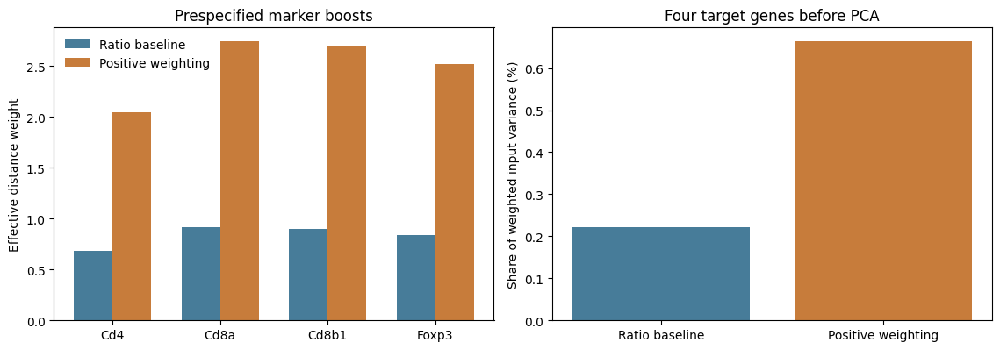

Variance shares describe the PCA input, not guaranteed influence in the retained PCs.


In [5]:
_target = WEIGHT_AUDIT.set_index("gene").reindex(EXPERIMENT["boost_genes"])
_shares = EXPERIMENT["target_variance_share_before_pca"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1))
_x = np.arange(len(_target))
axes[0].bar(_x-0.18, _target.baseline_weight, width=0.36, label="Ratio baseline", color="#477c99")
axes[0].bar(_x+0.18, _target.positive_weight, width=0.36, label="Positive weighting", color="#c77c3b")
axes[0].set(xticks=_x, xticklabels=_target.index, ylabel="Effective distance weight",
            title="Prespecified marker boosts")
axes[0].legend(frameon=False)
axes[1].bar(["Ratio baseline", "Positive weighting"],
            [100*_shares["baseline"], 100*_shares["positive"]], color=["#477c99", "#c77c3b"])
axes[1].set(ylabel="Share of weighted input variance (%)", title="Four target genes before PCA")
fig.tight_layout()
fig.savefig(EXPERIMENT_DIR / "weight_audit.png", dpi=160, bbox_inches="tight")
plt.show()
print("Variance shares describe the PCA input, not guaranteed influence in the retained PCs.")

## 3. Run the main comparison and companion check on GPU

The numerical settings follow the working 08S workflow: **50 centered PCs**, **GPU Harmony by sample_id** with theta 1.0, **30-neighbor CAGRA**, **Leiden 0.2/0.4/0.6**, and **GPU UMAP**. All variants use the same settings and seed. Condition is kept for biological review and is not supplied as an integration covariate.

The launcher checks the complete source identity, effective weights, package versions, settings and output receipt before reusing a baseline. A compatible 08S result is copied into the new result folder so that 08S remains unchanged. Fresh analyses use separate processes and available GPU cards; GPU memory is not pooled across cards.

The GPU stage has a 100-minute allowance, with checkpoints for restart. Preparation and reporting add time. Changing the boost creates a separate experiment; rerunning identical settings resumes compatible work.

In [6]:
_gpu_started = time.perf_counter()
try:
    BRANCHES, RUN_DIR = positive_workflow.launch_experiment(
        EXPERIMENT, HELPER_DIR, RUNTIME, settings=GPU_SETTINGS,
        max_minutes=100.0, resume=True,
    )
except BaseException as _error:
    _failed_root = getattr(_error, "run_root", None)
    if _failed_root is not None:
        _diagnostic = report_tools.make_return_package(_failed_root, EXPERIMENT, {}, max_megabytes=25)
        _download = Path.cwd() / "08T_run_diagnostics.zip"
        shutil.copy2(_diagnostic, _download)
        display(FileLink(os.path.relpath(_download, Path.cwd()),
                         result_html_prefix="Return this run diagnostic ZIP: "))
    raise
GPU_SECONDS = time.perf_counter() - _gpu_started
print("GPU comparison minutes this invocation:", round(GPU_SECONDS/60, 2))
for _name, _path in BRANCHES.items():
    print(_name + ":", _path)

Copied compatible 08S baseline into isolated 08T output: /stash/data/nonclin/TBIO-8110_VisiumHD-Adagrasib-mouseTumor/derived_files/tbio8110_stardist_proseg_resolvi_v1/08_ct26_joint_scvi/CT26_diam50_100_mt10_g50_c100_scvi4k_latent30_seed17/18_tcell_soft_weight_harmony/705627dc1cca13001a48/runs/2750922e663f1158/weighted
Started positive060: logical visible GPU 0; all 590,247 T cells.
08T running: positive060; 1/4 complete; 0.9 min elapsed.
08T running: positive060; 1/4 complete; 1.2 min elapsed.
[positive060] [weighted] 590,247 cells × 18,486 genes on NVIDIA A10G; 21.81 GiB currently free. All cells retained.
[positive060] [weighted] load_and_transfer_features: starting
08T running: positive060; 1/4 complete; 1.4 min elapsed.
[positive060] [weighted] CSR 1.50 GiB; PCA working estimate 5.63 GiB (workspace estimate).
[positive060] [weighted] load_and_transfer_features: done in 11.9s
[positive060] [weighted] centered_randomized_gpu_pca: starting
08T running: positive060; 1/4 complete; 1.7 m

## 4. Review the main comparison using original expression

**Dot area:** fraction of all cells in the cluster with original count > 0.  
**Dot color:** mean original, unweighted log1p expression, including zeros.

The two methods share marker color limits. Lineage dotplots are generated at all three resolutions; state and environmental panels use resolution 0.4. The complete report includes sample/condition/depth UMAPs, condition-stratified plots, marker co-occurrence, and marker summaries by sample and within-sample depth quintile.

All cells contribute to statistics. Only UMAP display points are limited to 120,000 identical cells per comparison. The original global annotations and counts remain unchanged. The evidence-based graph scores are descriptive internal diagnostics, not typing accuracy; boosted-marker separation alone does not validate a subtype.

In [7]:
_review_started = time.perf_counter()
LOG_MARKERS, COUNT_MARKERS, MARKER_GENES, OBS = positive_workflow.load_marker_data(BASE_CACHE_DIR)
MAIN_METHODS = positive_workflow.load_methods(BRANCHES, OBS, ("baseline060", "positive060"))
MAIN_REVIEW_DIR = RUN_DIR / "review" / "main"
MAIN_REVIEW = marker_review.build_review(
    LOG_MARKERS, COUNT_MARKERS, MARKER_GENES, OBS, MAIN_METHODS, MAIN_REVIEW_DIR,
    sample_key="sample_id", condition_key="condition", depth_key="total_counts",
    cluster_keys=[f"leiden_{r:g}" for r in GPU_SETTINGS["resolutions"]],
    primary_cluster_key="leiden_0.4", max_plot_cells=120000,
    max_clusters_per_page=35, random_state=0, normalization_target_sum=10000.0,
)
MAIN_COMPARISON = pd.read_csv(MAIN_REVIEW_DIR / "method_comparison.csv")
display(MAIN_COMPARISON)
MAIN_DOMINANCE = report_tools.write_main_dominance_audit(MAIN_REVIEW_DIR)
display(MAIN_DOMINANCE[MAIN_DOMINANCE.near_single_transcript_pattern][
    ["method", "clustering", "cluster", "n_cells", "gene", "fraction_positive", "mean_count_when_detected"]])
del MAIN_METHODS
gc.collect()
MAIN_REVIEW_SECONDS = time.perf_counter() - _review_started

Review: aggregating original markers for baseline060 (590,247 cells).
Review: aggregating original markers for positive060 (590,247 cells).
Review complete in 0.7 min: /stash/data/nonclin/TBIO-8110_VisiumHD-Adagrasib-mouseTumor/derived_files/tbio8110_stardist_proseg_resolvi_v1/08_ct26_joint_scvi/CT26_diam50_100_mt10_g50_c100_scvi4k_latent30_seed17/19_tcell_positive_weight_harmony/c812e729a31418ed3534/runs/1661048b5e7306523724/review/main/review.html


,method,clustering,n_cells,n_clusters,n_clusters_under_100_cells,fraction_cells_in_clusters_under_100,largest_cluster_fraction,log_depth_eta_squared,sample_cramers_v_bias_corrected,condition_cramers_v_bias_corrected,observed_evidence_cluster_purity,n_cells_with_exclusive_observed_evidence,observed_evidence_cluster_cramers_v,observed_evidence_graph_assortativity,evidence_graph_coverage_fraction
0,baseline060,leiden_0.2,590247,3,0,0.0,0.663460,0.195049,0.211839,0.108691,0.828107,46593,0.039253,0.232334,0.972571
1,baseline060,leiden_0.4,590247,9,0,0.0,0.294756,0.443770,0.144130,0.142821,0.828107,46593,0.055441,0.232334,0.972571
2,baseline060,leiden_0.6,590247,15,0,0.0,0.204420,0.479641,0.131372,0.155098,0.828107,46593,0.062771,0.232334,0.972571
3,positive060,leiden_0.2,590247,8,0,0.0,0.480138,0.264166,0.157200,0.137784,0.962569,46593,0.750896,0.952740,0.989741
4,positive060,leiden_0.4,590247,12,0,0.0,0.183269,0.472816,0.139564,0.163335,0.971884,46593,0.766131,0.952740,0.989741
5,positive060,leiden_0.6,590247,16,0,0.0,0.164301,0.465247,0.141797,0.164445,0.972185,46593,0.768289,0.952740,0.989741


,method,clustering,cluster,n_cells,gene,fraction_positive,mean_count_when_detected
876,baseline060,leiden_0.6,7,13026,Trac,0.998848,1.065176
1082,baseline060,leiden_0.6,11,15659,Nkg7,0.998659,1.082747
1127,baseline060,leiden_0.6,12,5611,Ccl5,0.996079,1.160673
1772,positive060,leiden_0.4,3,18251,Nkg7,0.999616,1.092030
2324,positive060,leiden_0.6,3,15830,Nkg7,0.997726,1.081867
2578,positive060,leiden_0.6,9,8797,Trac,0.999091,1.054045


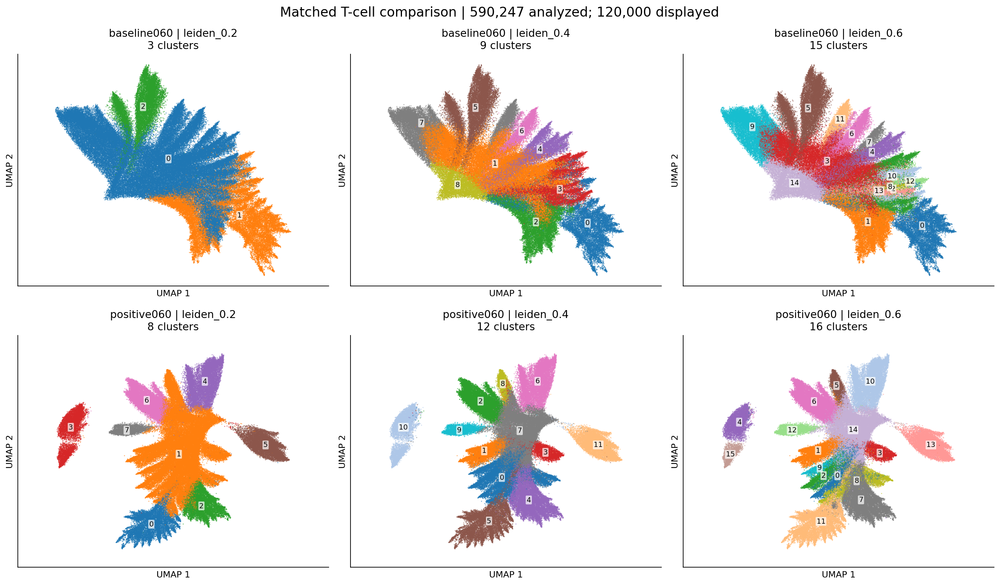

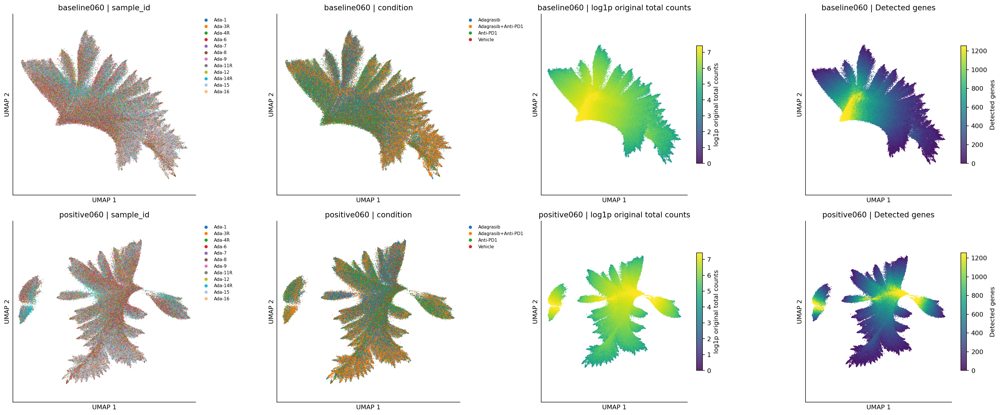

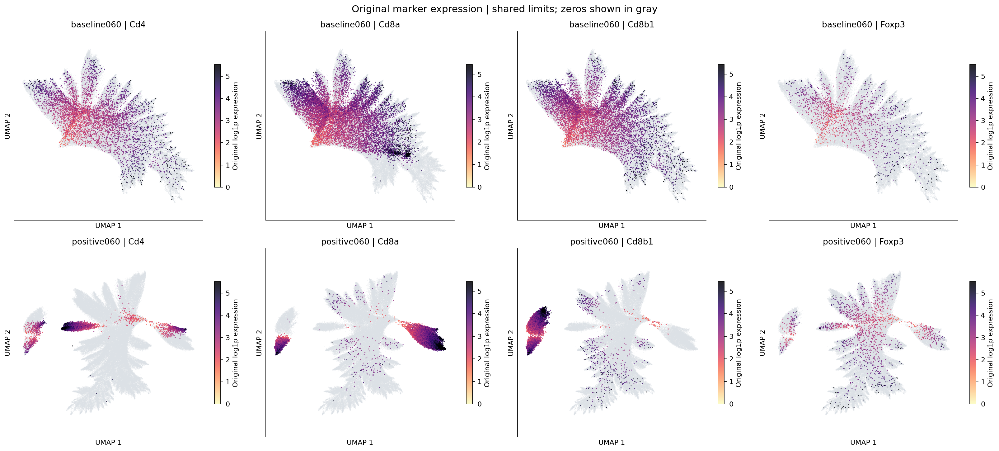

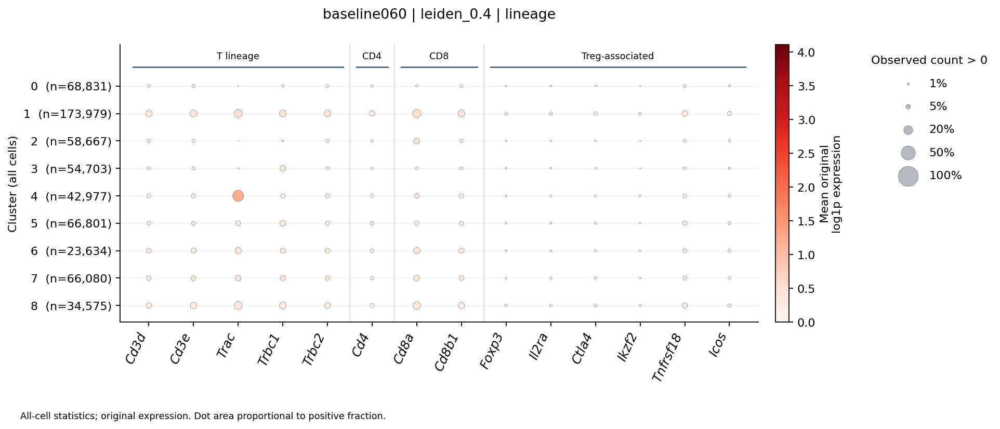

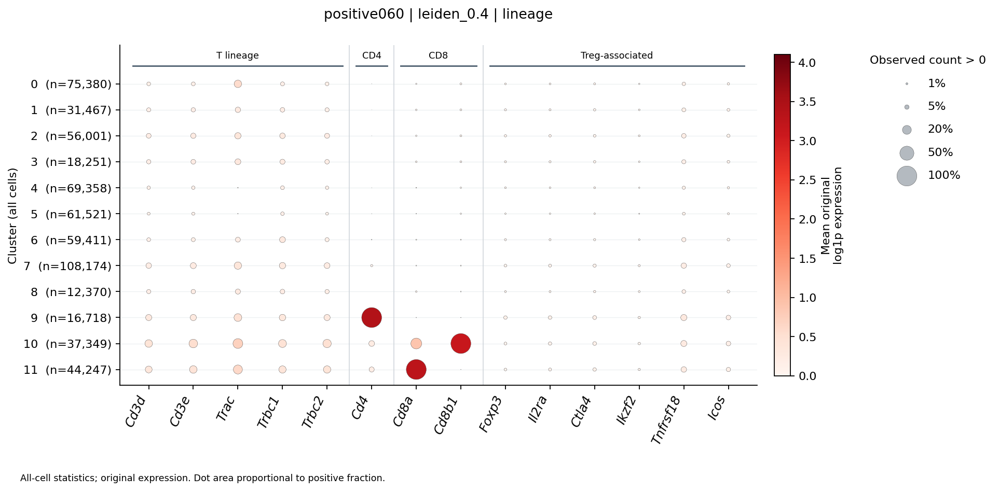

In [8]:
for _filename in ("umap_clusters.png", "umap_sample_condition_depth.png", "umap_lineage_markers.png"):
    display(Image(filename=str(MAIN_REVIEW_DIR / "figures" / _filename), width=1150))
for _method in ("baseline060", "positive060"):
    for _path in sorted((MAIN_REVIEW_DIR / "figures").glob(
            f"dotplot_{_method}_leiden_0_4_lineage_mean_log1p_page*.png")):
        display(Image(filename=str(_path), width=1100))

## 5. Check companion markers that were withheld from the embedding

This is a separate **matched pair**. Both reference and guided embeddings exclude the same five companion genes. Compare **heldout_baseline060 against heldout_positive060**; the main all-feature baseline is not the reference for this diagnostic.

The check asks whether Cd8a-associated organization gains support from **reserved Cd8b1**, and whether Foxp3-associated organization gains support from **reserved Il2ra, Ctla4, Ikzf2 and Tnfrsf18**. It verifies that the actual saved embedding weights for those genes are zero.

The added report summarizes original companion detection in clusters and among graph neighbors, with comparisons within samples and depth strata. It also flags groups with near-universal detection of Trac, Nkg7 or Ccl5 and counts close to one transcript per cell. Such flags request review; they do not identify artifacts automatically.

The companion results are descriptive evidence of program coherence. They provide neither ground-truth labels nor an independent validation of CD4 identity. Original full-library normalization is shared across the experiment; the held-out check isolates explicit gene features, not every possible statistical dependence in the data.

Review: aggregating original markers for heldout_baseline060 (590,247 cells).
Review: aggregating original markers for heldout_positive060 (590,247 cells).
Review complete in 0.5 min: /stash/data/nonclin/TBIO-8110_VisiumHD-Adagrasib-mouseTumor/derived_files/tbio8110_stardist_proseg_resolvi_v1/08_ct26_joint_scvi/CT26_diam50_100_mt10_g50_c100_scvi4k_latent30_seed17/19_tcell_positive_weight_harmony/c812e729a31418ed3534/runs/1661048b5e7306523724/review/heldout/review.html
Companion review: heldout_baseline060; original markers for all 590,247 cells.
Companion review: heldout_positive060; original markers for all 590,247 cells.
Held-out companion review complete: /stash/data/nonclin/TBIO-8110_VisiumHD-Adagrasib-mouseTumor/derived_files/tbio8110_stardist_proseg_resolvi_v1/08_ct26_joint_scvi/CT26_diam50_100_mt10_g50_c100_scvi4k_latent30_seed17/19_tcell_positive_weight_harmony/c812e729a31418ed3534/runs/1661048b5e7306523724/review/companion/companion_review.html


,method,gene,original_assay_available,in_feature_universe,effective_input_weight,excluded_from_embedding,completed_embedding_weight_checked,original_n_positive,original_fraction_positive
0,heldout_baseline060,Cd8b1,True,True,0.0,True,True,40219,0.068139
1,heldout_baseline060,Il2ra,True,True,0.0,True,True,8889,0.015060
2,heldout_baseline060,Ctla4,True,True,0.0,True,True,10845,0.018374
3,heldout_baseline060,Ikzf2,True,True,0.0,True,True,5099,0.008639
4,heldout_baseline060,Tnfrsf18,True,True,0.0,True,True,30269,0.051282
5,heldout_positive060,Cd8b1,True,True,0.0,True,True,40219,0.068139
6,heldout_positive060,Il2ra,True,True,0.0,True,True,8889,0.015060
7,heldout_positive060,Ctla4,True,True,0.0,True,True,10845,0.018374
8,heldout_positive060,Ikzf2,True,True,0.0,True,True,5099,0.008639
9,heldout_positive060,Tnfrsf18,True,True,0.0,True,True,30269,0.051282


,method,guide_gene,heldout_gene,marker_pair_available,graph_available,n_samples_compared,n_shared_depth_strata,n_guide_positive_compared,n_guide_negative_compared,global_heldout_detection_fraction,sample_balanced_raw_neighbor_difference,sample_balanced_neighbor_excess_difference,n_samples_with_positive_excess_difference,graph_nonself_neighbor_coverage
0,heldout_baseline060,Cd8a,Cd8b1,True,True,12,60,56943,533304,0.068139,0.062287,0.049965,12,1.0
1,heldout_baseline060,Foxp3,Il2ra,True,True,12,60,7990,582257,0.015060,0.007562,0.006358,12,1.0
2,heldout_baseline060,Foxp3,Ctla4,True,True,12,60,7990,582257,0.018374,0.008813,0.007298,12,1.0
3,heldout_baseline060,Foxp3,Ikzf2,True,True,12,60,7990,582257,0.008639,0.004640,0.003751,12,1.0
4,heldout_baseline060,Foxp3,Tnfrsf18,True,True,12,60,7990,582257,0.051282,0.019187,0.015801,12,1.0
5,heldout_positive060,Cd8a,Cd8b1,True,True,12,60,56943,533304,0.068139,0.080233,0.059525,12,1.0
6,heldout_positive060,Foxp3,Il2ra,True,True,12,60,7990,582257,0.015060,0.008382,0.007179,12,1.0
7,heldout_positive060,Foxp3,Ctla4,True,True,12,60,7990,582257,0.018374,0.009930,0.008421,12,1.0
8,heldout_positive060,Foxp3,Ikzf2,True,True,12,60,7990,582257,0.008639,0.004656,0.003762,12,1.0
9,heldout_positive060,Foxp3,Tnfrsf18,True,True,12,60,7990,582257,0.051282,0.022486,0.019009,12,1.0


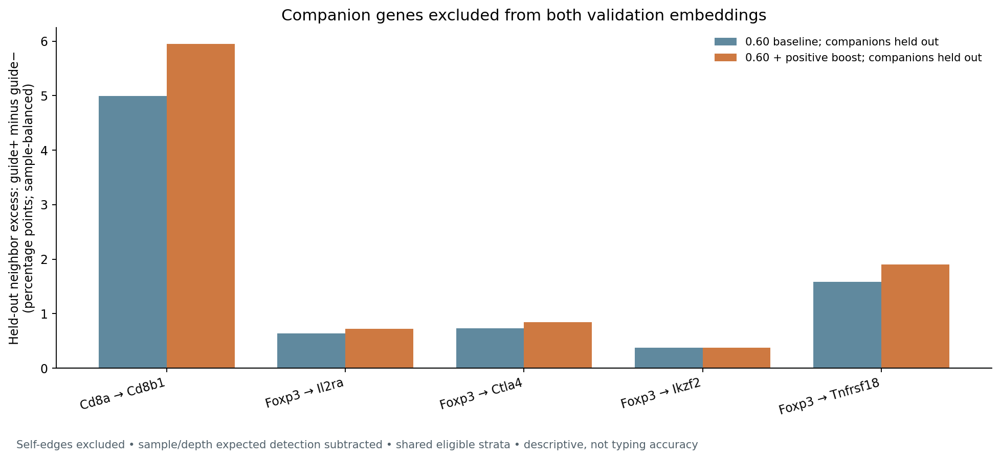

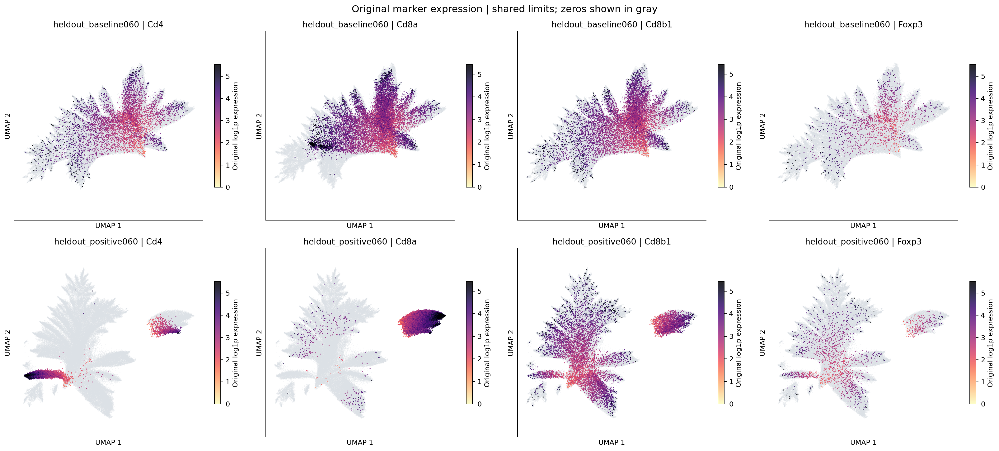

3636

In [9]:
_heldout_started = time.perf_counter()
_heldout_names = ("heldout_baseline060", "heldout_positive060")
HELDOUT_METHODS = positive_workflow.load_methods(BRANCHES, OBS, _heldout_names)
HELDOUT_FEATURE_TABLES = {
    _name: pd.read_csv(Path(EXPERIMENT["variants"][_name]["cache_dir"]) / "features.csv")
    for _name in _heldout_names
}
HELDOUT_REVIEW_DIR = RUN_DIR / "review" / "heldout"
HELDOUT_REVIEW = marker_review.build_review(
    LOG_MARKERS, COUNT_MARKERS, MARKER_GENES, OBS, HELDOUT_METHODS, HELDOUT_REVIEW_DIR,
    sample_key="sample_id", condition_key="condition", depth_key="total_counts",
    cluster_keys=["leiden_0.4"], primary_cluster_key="leiden_0.4",
    max_plot_cells=120000, max_clusters_per_page=35, random_state=0,
    normalization_target_sum=10000.0,
)
COMPANION_DIR = RUN_DIR / "review" / "companion"
COMPANION = companion_review.build_companion_review(
    COUNT_MARKERS, LOG_MARKERS, MARKER_GENES, OBS,
    HELDOUT_METHODS, HELDOUT_FEATURE_TABLES, COMPANION_DIR,
    primary_cluster_key="leiden_0.4", heldout_genes=EXPERIMENT["heldout_genes"],
)
HELDOUT_SECONDS = time.perf_counter() - _heldout_started
display(pd.read_csv(COMPANION_DIR / "heldout_exclusion_audit.csv"))
display(pd.read_csv(COMPANION_DIR / "heldout_neighbor_summary.csv"))
display(Image(filename=str(COMPANION_DIR / COMPANION["figure"]), width=1150))
display(Image(filename=str(HELDOUT_REVIEW_DIR / "figures" / "umap_lineage_markers.png"), width=1150))
del HELDOUT_METHODS
gc.collect()

## 6. Save the reports and compact return file

The reports contain complete all-cell marker tables and figures. The **return ZIP** contains aggregate tables, weight audits, timing/version records and prioritized figures; it excludes the large H5ADs and expression matrices. Selected input files are capped near 25 MB before compression, with omitted figures listed in `PACKAGE_CONTENTS.json`.

Convenient report copies are placed in **08T_results** under the notebook's working folder. The original analysis outputs remain in **19_tcell_positive_weight_harmony**.

In [ ]:
TIMINGS = {
    "setup_seconds": SETUP_SECONDS,
    "preparation_seconds_this_invocation": PREPARE_SECONDS,
    "gpu_seconds_this_invocation": GPU_SECONDS,
    "main_review_seconds": MAIN_REVIEW_SECONDS,
    "heldout_review_seconds": HELDOUT_SECONDS,
    "note": "GPU variants may overlap; reused baseline work can originate in an earlier invocation.",
}
REVIEW_DIRS = {"main": MAIN_REVIEW_DIR, "heldout": HELDOUT_REVIEW_DIR, "companion": COMPANION_DIR}
REPORT_INDEX = report_tools.build_report_index(RUN_DIR, EXPERIMENT, REVIEW_DIRS, timings=TIMINGS)
RETURN_ZIP = report_tools.make_return_package(RUN_DIR, EXPERIMENT, REVIEW_DIRS, max_megabytes=25)
LOCAL_RESULTS = Path.cwd() / "08T_results" / (EXPERIMENT["experiment_id"][:8] + "_" + RUN_DIR.name)
LOCAL_RESULTS.mkdir(parents=True, exist_ok=True)
shutil.copytree(RUN_DIR / "review", LOCAL_RESULTS / "review", dirs_exist_ok=True)
shutil.copy2(REPORT_INDEX, LOCAL_RESULTS / "review.html")
shutil.copy2(RETURN_ZIP, LOCAL_RESULTS / RETURN_ZIP.name)
display(Markdown("### Ready to inspect"))
display(FileLink(os.path.relpath(LOCAL_RESULTS / "review.html", Path.cwd()),
                 result_html_prefix="All reports: "))
display(FileLink(os.path.relpath(LOCAL_RESULTS / RETURN_ZIP.name, Path.cwd()),
                 result_html_prefix="Return this ZIP: "))
print("Complete report:", (LOCAL_RESULTS / "review.html").resolve())
print("Return ZIP:", (LOCAL_RESULTS / RETURN_ZIP.name).resolve())
display(pd.DataFrame([{
    k.replace("_seconds", "_minutes"): round(v/60, 2)
    for k, v in TIMINGS.items() if isinstance(v, (int, float))
}]))

Return file: /stash/data/nonclin/TBIO-8110_VisiumHD-Adagrasib-mouseTumor/derived_files/tbio8110_stardist_proseg_resolvi_v1/08_ct26_joint_scvi/CT26_diam50_100_mt10_g50_c100_scvi4k_latent30_seed17/19_tcell_positive_weight_harmony/c812e729a31418ed3534/runs/1661048b5e7306523724/08T_return_to_chat.zip (22.3 MB)


## What would count as improvement?

Look for several kinds of support together:

1. **Original-expression coherence:** CD4- and CD8-associated evidence becomes more differentiated, with several T-lineage companions supporting the pattern. Foxp3-rich groups gain additional Treg-associated evidence.
2. **Held-out support:** the guided diagnostic improves organization of companions that contributed zero to its embedding, compared with its matched held-out baseline.
3. **Sample and depth consistency:** the contrast recurs across samples and comparable count strata. Lower sample/condition association alone is not success; treatment-related biology should remain interpretable.
4. **Limited single-gene dependence:** inspect Trac/Nkg7/Ccl5 dominance flags and whether apparent lineages are supported by more than one measured gene.

More clusters, a more branched UMAP, or a higher internal marker score alone do not establish successful typing. The notebook deliberately retains uncertainty instead of assigning every cell a subtype. Cluster IDs are arbitrary and are not matched across variants or resolutions.

The first test is deliberately modest. To evaluate a later boost strength, change only `POSITIVE_BOOST` and Run All; the notebook makes a new experiment while retaining prior results and reusing compatible input arrays. The boost is applied on top of the ratio curve and does not remove environmental transcripts or recover unobserved molecules.

## Methods and validation

The notebook extends the working 08S sparse GPU PCA/Harmony pipeline. GPU PCA uses implicit centering and a randomized range finder with reorthogonalization and thin SVD; it never creates a dense cell-by-gene matrix. Harmony uses a shared PCA basis across samples and the original Harmony flavor when that option is available. Separate sample-specific PC bases are not concatenated.

Build validation includes synthetic CPU comparisons to a directly centered dense SVD, exact-zero holdout invariance, source preservation, cache identities and baseline compatibility, companion-report calculations, notebook validation and embedded-helper integrity. Actual CUDA execution and biological performance must be checked by this notebook on the user's instance. See `VALIDATION.md` in the optional package for completed checks and limits.

References:

- [Randomized matrix decompositions: Halko, Martinsson and Tropp](https://arxiv.org/abs/0909.4061).
- [RAPIDS GPU Harmony integration](https://rapids-singlecell.scverse.org/en/stable/api/generated/rapids_singlecell.pp.harmony_integrate.html).
- [RAPIDS GPU neighbor graph](https://rapids-singlecell.scverse.org/en/stable/api/generated/rapids_singlecell.pp.neighbors.html).
- [Mouse T-cell lineage and state reference: ProjecTILs](https://doi.org/10.1038/s41467-021-23324-4).

The positive boost is this project's prespecified experiment, not an implementation of SAM or a trained cell-type classifier.